# Módulo de IA: Predicción de Inasistencia a Citas Odontológicas (No-Show)
## 1. Definición del Problema Empresarial
El centro dental pierde ingresos operativos y los pacientes interrumpen su progreso clínico cuando faltan a sus citas programadas. Este modelo de Machine Learning clasifica cada cita agendada para predecir la probabilidad de inasistencia (`Target_Inasistencia`), permitiendo a la clínica priorizar recordatorios y calcular el ingreso en riesgo.

### Importación de librerías y conexión a Base Dimensional

In [8]:
import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Conexión a la base de datos
SERVER = r'localhost\SQLEXPRESS'
DM_DB = 'DentalCenterDB'
driver = [d for d in pyodbc.drivers() if 'SQL Server' in d][-1]
conn_str = f'DRIVER={{{driver}}};SERVER={SERVER};DATABASE={DM_DB};Trusted_Connection=yes;TrustServerCertificate=yes;'
conn = pyodbc.connect(conn_str)
print("Conectado al DataMart exitosamente.")

Conectado al DataMart exitosamente.


## 2. Extracción y Análisis Exploratorio de Datos (EDA)
Se extrae la sábana de datos desde la vista `dm.vw_Dataset_ML`. Convertiremos variables categóricas simples (como el Género) a numéricas para poder evaluar su correlación estadística con la variable objetivo.

C:\Users\fabri\AppData\Local\Temp\ipykernel_5076\2573120658.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)
C:\Users\fabri\AppData\Local\Temp\ipykernel_5076\2573120658.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Target_Inasistencia', data=df, palette='viridis')


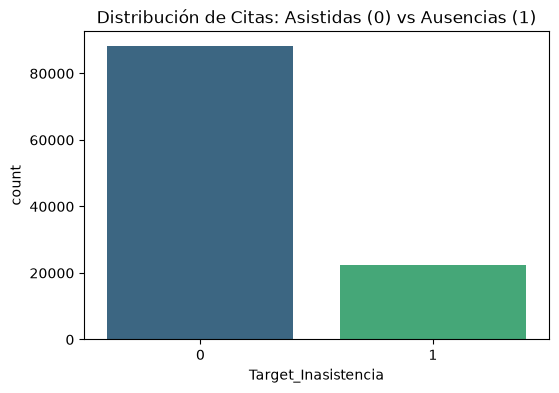

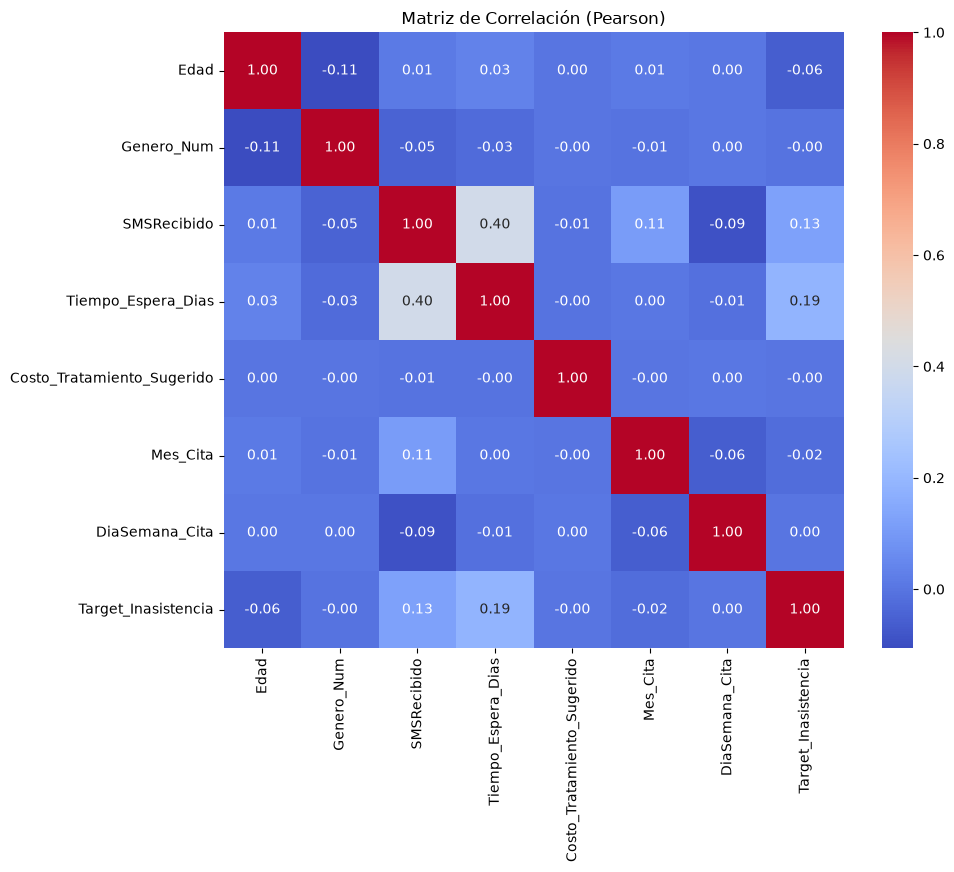

In [9]:
# Extracción desde la vista actualizada
query = "SELECT * FROM dm.vw_Dataset_ML"
df = pd.read_sql(query, conn)

# Preprocesamiento rápido: Convertir 'Genero' a variable binaria (F=0, M=1) para la matriz
df['Genero_Num'] = df['Genero'].map({'F': 0, 'M': 1})

# Visualización del desbalance de la variable objetivo
plt.figure(figsize=(6,4))
sns.countplot(x='Target_Inasistencia', data=df, palette='viridis')
plt.title('Distribución de Citas: Asistidas (0) vs Ausencias (1)')
plt.show()

# Matriz de Correlación
cols_numericas = ['Edad', 'Genero_Num', 'SMSRecibido', 'Tiempo_Espera_Dias', 
                  'Costo_Tratamiento_Sugerido', 'Mes_Cita', 'DiaSemana_Cita', 'Target_Inasistencia']

plt.figure(figsize=(10,8))
sns.heatmap(df[cols_numericas].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación (Pearson)')
plt.show()

## 3. Selección de Variables y División del Dataset
> **Análisis del EDA:** *(Redactarás aquí tus hallazgos tras ver la matriz con la data real. Por ejemplo: Se observa que `Tiempo_Espera_Dias` tiene la mayor correlación positiva con la inasistencia).*

Dividiremos los datos en 80% entrenamiento y 20% prueba, aplicando estratificación (`stratify=y`) para garantizar que la proporción de inasistencias se mantenga en ambos conjuntos.

In [10]:
df_modelo = df.copy()
# Definición de variables predictoras (X) y objetivo (y)
X = df[['Edad', 'Genero_Num', 'SMSRecibido', 'Tiempo_Espera_Dias', 
        'Costo_Tratamiento_Sugerido', 'Mes_Cita', 'DiaSemana_Cita']]
y = df['Target_Inasistencia']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Entrenamiento: {X_train.shape[0]} citas | Prueba: {X_test.shape[0]} citas.")

Entrenamiento: 88407 citas | Prueba: 22102 citas.


## 4. Entrenamiento y Evaluación de Algoritmos
Entrenaremos una **Regresión Logística** (modelo base) y un **Random Forest**. Priorizaremos la métrica de **Recall**, ya que nos interesa capturar la mayor cantidad posible de pacientes que van a faltar, asumiendo que enviar un recordatorio extra (Falso Positivo) es muy barato frente al ingreso perdido de una silla vacía (Falso Negativo).

--- REGRESIÓN LOGÍSTICA (Balanceada) ---
Accuracy: 0.6637 | Recall: 0.5686 | F1: 0.4057

--- RANDOM FOREST (Balanceado + Umbral 0.40) ---
Accuracy: 0.5201 | Recall: 0.9229 | F1: 0.4371


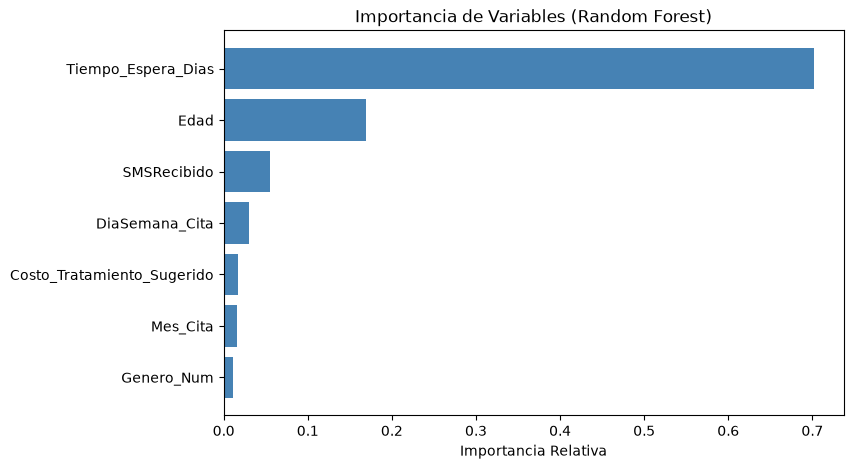

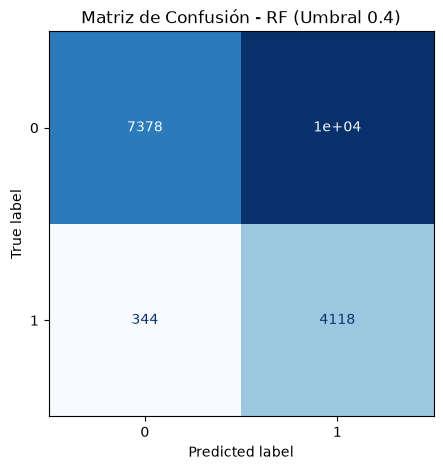

In [11]:
# 1. Regresión Logística (con balanceo de clases)
lr_model = LogisticRegression(max_iter=2000, class_weight='balanced')
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 2. Random Forest (con balanceo de clases)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10, class_weight='balanced')
rf_model.fit(X_train, y_train)

# 3. Ajuste de Umbral para el Random Forest (Priorizando el Recall del Negocio)
umbral_decision = 0.40 # Si hay 40% de prob. de falta, lo marcamos como riesgo.
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_rf_custom = (y_prob_rf >= umbral_decision).astype(int)

# Métricas
print("--- REGRESIÓN LOGÍSTICA (Balanceada) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f} | Recall: {recall_score(y_test, y_pred_lr):.4f} | F1: {f1_score(y_test, y_pred_lr):.4f}")

print("\n--- RANDOM FOREST (Balanceado + Umbral 0.40) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf_custom):.4f} | Recall: {recall_score(y_test, y_pred_rf_custom):.4f} | F1: {f1_score(y_test, y_pred_rf_custom):.4f}")

# Gráfico: Importancia de Variables (Feature Importance)
importancias = rf_model.feature_importances_
indices = np.argsort(importancias)

plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importancias[indices], color='steelblue', align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel('Importancia Relativa')
plt.title('Importancia de Variables (Random Forest)')
plt.show()

# Matriz de Confusión (con el nuevo umbral)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf_custom, cmap='Blues', ax=ax, colorbar=False)
plt.title(f'Matriz de Confusión - RF (Umbral {umbral_decision})')
plt.show()

## 5. Integración BI: Exportación de Resultados
Basado en las métricas, se selecciona el **Random Forest**. Para asegurar que el negocio actúe de forma preventiva, clasificamos las probabilidades en niveles de riesgo y exportamos los resultados a la tabla `dm.Resultados_Prediccion_IA` para que Power BI alimente su simulador financiero.

In [12]:
# Predecir probabilidades para todo el dataset original
probabilidades = rf_model.predict_proba(X)[:, 1]
df['Prob_Inasistencia'] = probabilidades

# Ajuste de umbrales para niveles de riesgo
def asignar_riesgo(prob):
    if prob >= 0.50: return 'Riesgo Alto'
    elif prob >= 0.25: return 'Riesgo Medio'
    else: return 'Riesgo Bajo'

df['Nivel_Riesgo'] = df['Prob_Inasistencia'].apply(asignar_riesgo)
df['Prediccion_Binary'] = (probabilidades >= 0.50).astype(int)

# Exportación a SQL Server (Tabla: dm.Resultados_Prediccion_IA)
cursor = conn.cursor()
cursor.execute("TRUNCATE TABLE dm.Resultados_Prediccion_IA;")

# Inserción masiva usando executemany para mayor velocidad
insert_query = """
    INSERT INTO dm.Resultados_Prediccion_IA 
    (IdCita, SK_Paciente, Probabilidad_Inasistencia, Nivel_Riesgo, Prediccion_Binary)
    VALUES (?, ?, ?, ?, ?)
"""

# Preparamos los datos como lista de tuplas
datos_insert = [
    (int(row['IdCita']), int(row['SK_Paciente']), float(row['Prob_Inasistencia']), 
     row['Nivel_Riesgo'], int(row['Prediccion_Binary']))
    for _, row in df.iterrows()
]

cursor.executemany(insert_query, datos_insert)
conn.commit()
cursor.close()
conn.close()

print(f"¡Integración exitosa! {len(datos_insert)} predicciones exportadas a SQL Server.")

¡Integración exitosa! 110509 predicciones exportadas a SQL Server.
